# Korpus aufbauen

In [116]:
import os

corpus = [] #initial empty list

os.getcwd() #get current path

data_folder = os.path.join(os.getcwd(), "korpus") #join current path with directory name
print(list(os.walk(data_folder))) #check files inside of chosen directory

for root, folders, files in os.walk(data_folder): #structure of list is root -> folders -> files
    for file in files:
        path = os.path.join(root, file)
        with open(path, encoding="utf8") as input: #encode in utf8 for special characters like ä.ü,ö,ß
            corpus.append(input.read()) #append every file as new list-item
input.close()

print(len(corpus),"Texte wurden erfolgreich in den Korpus geladen.")


[('c:\\workspace\\nlp-lernen\\korpus', [], ['aanrud_sidsel_langroeckchen.txt', 'achleitner-Im_gruenen_Tann.txt', 'achleitner-Unter_den_Hohen_Tauern.txt', 'alarcon-Der Dreispitz.txt', 'alberti-Japanische Märchen.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 40.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 42.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 56.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 63.txt', 'goethe-faust1.txt', 'goethe-faust2.txt', 'goethe-leiden_des_jungen_werther.txt', 'kafka-landarzt.txt', 'kafka-urteil.txt', 'kafka-verwandlung.txt', 'nietzsche-Der tolle Mensch.txt', 'schiller-raeuber.txt', 'Skowronnek-Sturmzeichen.txt', 'westermann-Die Nutzpflanzen unserer Kolonien und ihre wirtschaftliche Bedeutung für das Mutterland.txt'])]
19 Texte wurden erfolgreich in den Korpus geladen.


In [181]:
import nltk
from nltk.text import Text
from nltk.probability import FreqDist
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
import numpy as np
import spacy
from textstat.textstat import textstatistics

corpus_list = []
#corpus_vec = []
corpus_name = []

#Type-Token-Ratio (TTR)
def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0 #make set without duplicates and divide with all tokens (incl. duplicates); if list is empty, dont divide with 0 just say, its 0

def punctuations(tokens):
    excl = 0
    quest = 0
    pct = 0
    com = 0
    semic = 0
    colo = 0

    for i in tokens:
        if i == "!":
            excl += 1
        if i == "?":
            quest += 1
        if i == ".":
            pct += 1
        if i == ",":
            com += 1
        if i == ";":
            semic += 1
        if i == ":":
            colo += 1

    erg_excl = excl / len(tokens)
    erg_quest = quest / len(tokens)
    erg_pct = pct / len(tokens)
    erg_com = com / len(tokens)
    erg_semic = semic / len(tokens)
    erg_colo = colo / len(tokens)

    return erg_excl, erg_quest, erg_pct, erg_com, erg_semic, erg_colo

def syllables_count(word):
    return textstatistics().syllable_count(word)

def avg_syllables_per_word(text, words):
    syllable = syllables_count(text)
    ASPW = float(syllable) / float(words)
    #print("Ergebnis von Silben / Wörter:",ASPW)
    return round(ASPW, 1)

def flesch_reading_ease(asl, asw):
    
    fre = 180 - asl - (58.5 - asw)
    
    return round(fre,2)


for element in corpus:
    text = element

    nltk_text = Text(nltk.word_tokenize(text.lower())) #lower, damit es keine Doppelungen beim zählen später gibt
    #print("Anzahl Token im Text:",len(nltk_text))
    #print("NLTK:",nltk_text)

    nltk_text_words = [t for t in nltk_text if t.isalpha()]  # Entferne Satzzeichen/Zahlen
    number_words = len(nltk_text_words)
    #print("Wörter im Dokument:",number_words)

    sentences = nltk.sent_tokenize(text) #tokenize in sentences
    number_sentences = len(sentences)
    #print("Sätze im Dokument:",number_sentences) #number of sentences

    avg_sen_len = round(len(nltk_text_words) / len(sentences),1) #average sentence length
    #print(avg_sen_len)
    avg_word_len = round(sum(len(word) for word in nltk_text_words) / len(nltk_text_words),1)
    #print(avg_word_len)
    
    ttr_erg = round(ttr(nltk_text_words),2)
    avg_punct = punctuations(nltk_text)
    
    avg_syll = avg_syllables_per_word(text,number_words)
    fre_ger = flesch_reading_ease(avg_sen_len, avg_syll)
    #print(avg_sen_len, avg_word_len, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3))
    print(number_words, number_sentences, avg_sen_len, avg_word_len, fre_ger)

    #corpus_list.append([avg_sen_len, avg_word_len, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)]) #Ohne Punkt, Anzahl Wörter und Sätze
    corpus_list.append([number_sentences, avg_sen_len, avg_word_len, fre_ger])
    corpus_name.append(nltk_text)

    #print("-----------------------------------------------")

corpus_vec = np.array(corpus_list)
corpus_matrix = cosine_distances(corpus_vec)

30780 1472 20.9 4.8 101.9
56687 2870 19.8 5.3 103.0
66368 4203 15.8 5.5 107.1
29112 1433 20.3 5.0 102.6
30760 1282 24.0 4.9 98.8
15963 958 16.7 5.3 106.2
16156 936 17.3 5.4 105.6
14713 848 17.4 5.3 105.5
14403 890 16.2 5.4 106.7
33739 3932 8.6 4.8 114.1
48063 3493 13.8 5.1 109.2
3272 132 24.8 5.0 98.4
16059 728 22.1 5.1 100.7
6961 319 21.8 5.0 101.2
22081 779 28.3 5.1 94.5
3216 132 24.4 5.0 98.8
43689 4155 10.5 4.9 112.6
71987 4250 16.9 5.2 105.9
21156 1674 12.6 5.6 110.7


In [186]:
corpus_matrix = cosine_distances(corpus_vec)
corpus_matrix

array([[0.00000000e+00, 5.79807755e-04, 1.00794930e-03, 2.81249007e-06,
        4.06882212e-05, 8.59590640e-04, 9.45903203e-04, 1.51647951e-03,
        1.27100958e-03, 8.77806401e-04, 7.70410788e-04, 1.66532554e-01,
        2.46583953e-03, 2.95045146e-02, 1.57488783e-03, 1.67288605e-01,
        9.52562639e-04, 1.03063229e-03, 2.68856519e-05],
       [5.79807755e-04, 0.00000000e+00, 5.91075533e-05, 6.61140504e-04,
        9.13109376e-04, 2.83675865e-03, 2.99529995e-03, 3.95998935e-03,
        3.54998054e-03, 3.48279088e-05, 1.50881256e-05, 1.85817019e-01,
        5.43341462e-03, 3.82766609e-02, 4.03054546e-03, 1.86614707e-01,
        4.83045654e-05, 6.45193399e-05, 4.56048210e-04],
       [1.00794930e-03, 5.91075533e-05, 0.00000000e+00, 1.11381966e-03,
        1.43664140e-03, 3.70446205e-03, 3.88648012e-03, 4.97600076e-03,
        4.51262682e-03, 7.48311561e-06, 1.67107479e-05, 1.92171911e-01,
        6.62145085e-03, 4.13037607e-02, 5.06386908e-03, 1.92980232e-01,
        2.07433918e-06

# Heatmap zeichnen

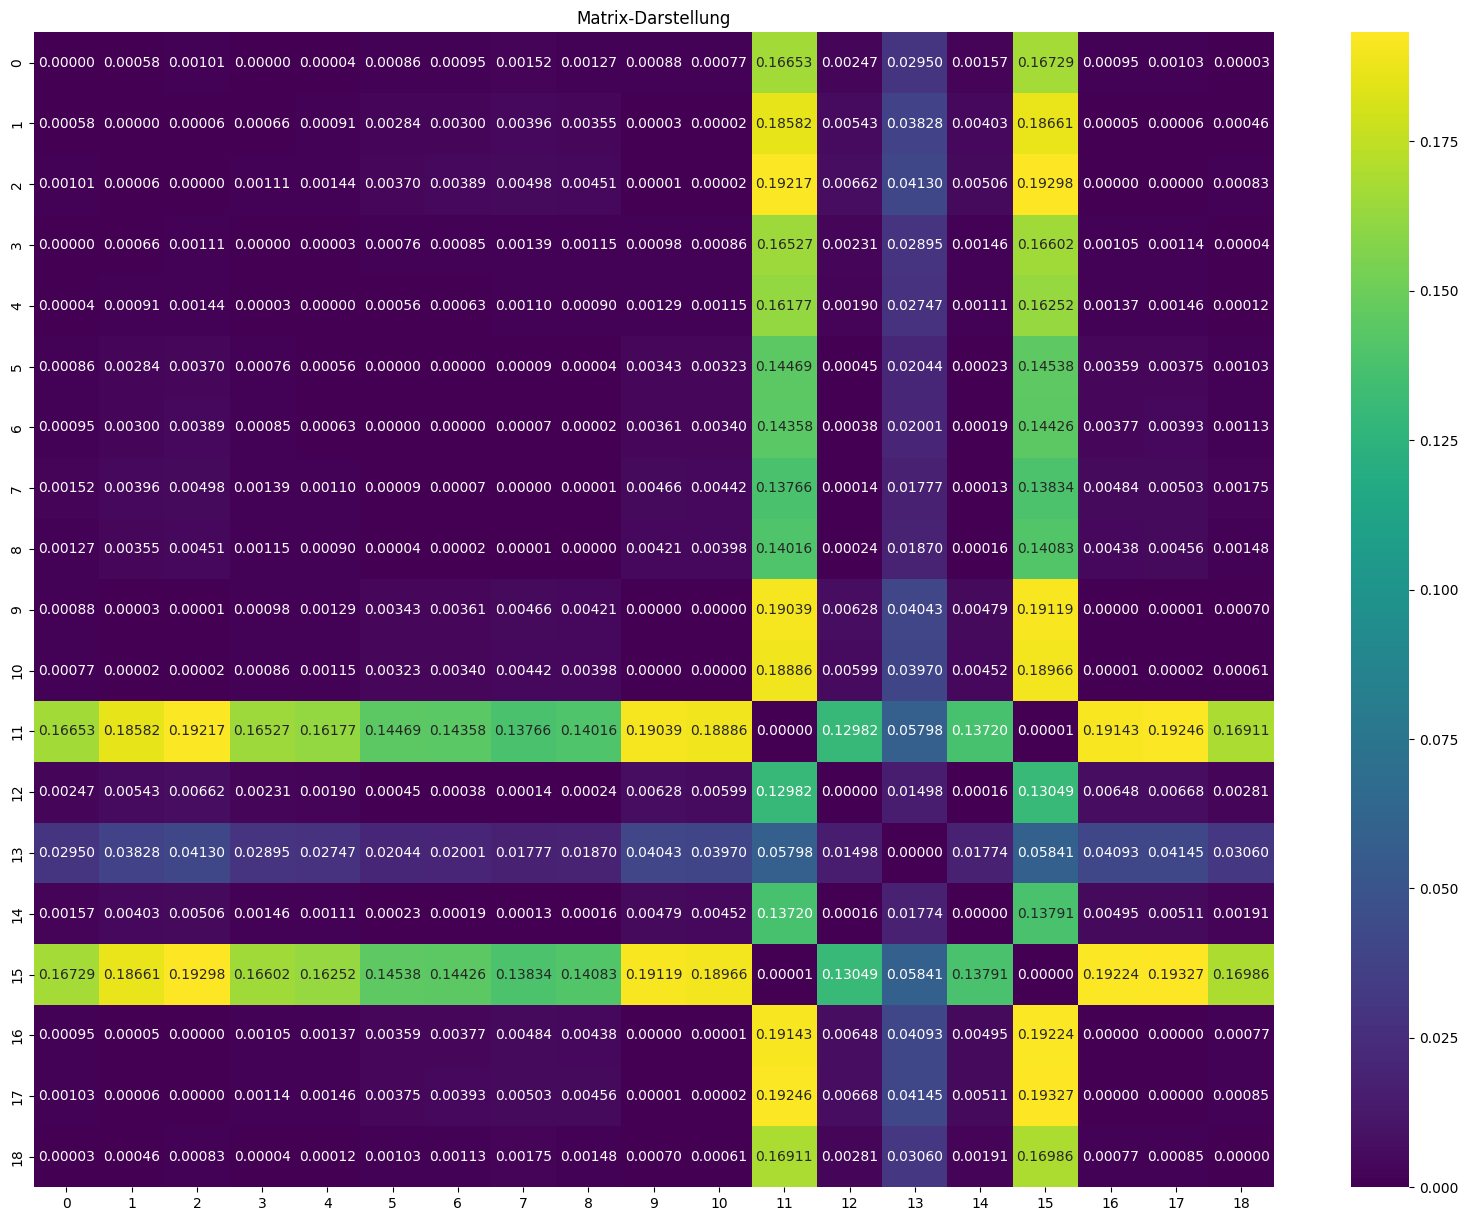

In [187]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(corpus_matrix)

plt.figure(figsize=(20, 15))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("Matrix-Darstellung")
plt.show()
